# Self-generated standing spin wave in the orthogonal biquadratic STO: from the dispersion relation to the frequency staircase

This notebook reproduces, step by step and with no hidden code, the numerical part of the analytical model
(`derivation.pdf`, Sections 3, 5, 7 and 8): how the gyration frequency $\omega$ of the free layer fixes the radial
wavenumber $k^*$ of the spin wave, how the disk then only admits a ladder of frequencies, and how that compares with
the micromagnetic data. The final cell produces the summary figure (`standing_wave_theory_notebook.png`, identical in content to Fig. 1 of the derivation).

**What is needed to run it**: Python 3 with `numpy`, `scipy`, `matplotlib`. The only inputs are three small CSV files in `data/`:

| file | content | origin |
|---|---|---|
| `data/derived/wave_table.csv` | one row per simulation run: gyration frequency $f$, dominant azimuthal index $m$, its power fraction, and the radial wavenumber $k$ measured from the phase slope of the $M_z$ FFT map | `wave_extract.py` applied to every `heat_map.npy` of the current sweep ($D=320$ nm) and of the diameter sweep |
| `data/derived/j_vs_freq_bq.csv`, `data/derived/j_vs_freq_no_bq.csv` | gyration frequency versus current density for the $D=320$ nm disk, with and without biquadratic coupling | the simulation post-processing used for Fig. 2 of the manuscript |

No micromagnetic data beyond these tables is touched, and nothing is fitted anywhere in the notebook.

**Notation and units.** The simulator integrates the Landau–Lifshitz–Gilbert equation in the form
$\dot{\mathbf m}=-\gamma\,\mathbf m\times\mathbf H+\alpha\,\mathbf m\times\dot{\mathbf m}$ with all fields in A/m and
$\gamma=2.211\times10^{5}\ \mathrm{m\,A^{-1}s^{-1}}$, so that a field $H$ produces the angular frequency $\omega=\gamma H$
($\gamma/2\pi=28.0$ GHz per tesla of $\mu_0H$). Frequencies are quoted in GHz, wavenumbers in rad/µm.

In [1]:
import numpy as np, csv
from scipy.optimize import brentq
from scipy.special import jn_zeros, jnp_zeros, j1
import matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})

# ---- physical constants and free-layer parameters (CoFe, as in the simulations) ----
mu0 = 4e-7*np.pi
gam = 2.211e5        # m A^-1 s^-1 ; omega = gam * H  (H in A/m)
Ms  = 1.35e6         # A/m
A   = 1.3e-11        # J/m
d   = 2e-9           # m   (free-layer thickness)
B12 = 0.6e-3         # J/m^2 (|B12|; the sign in the simulation is negative = orthogonal coupling)
R   = 160e-9         # m   (disk radius of the current sweep)

D  = 2*A/(mu0*Ms)            # exchange stiffness field constant, A m   (field = D k^2)
HB = 2*B12/(mu0*Ms*d)        # biquadratic field coefficient, A/m        (field = -HB m_z z)

print(f"D     = {D:.3e} A m")
print(f"HB    = {HB:.3e} A/m  = {mu0*HB:.3f} T   (compare mu0 Ms = {mu0*Ms:.3f} T)")
print(f"HB/Ms = {HB/Ms:.3f}  -> (Ms+HB)/Ms = {(Ms+HB)/Ms:.3f}")

D     = 1.533e-11 A m
HB    = 3.537e+05 A/m  = 0.444 T   (compare mu0 Ms = 1.696 T)
HB/Ms = 0.262  -> (Ms+HB)/Ms = 1.262


## 1. The gyrating state (Section 3)

The free layer gyrates rigidly in-plane with a constant tilt $m_{z0}=\sin\theta_0$. The only conservative fields on
a uniform film are along $z$: the thin-film demagnetising field $-M_sm_z\hat{\mathbf z}$ and the biquadratic field
$-H_Bm_z\hat{\mathbf z}$. Balancing their precession against the gyration gives

$$\omega=\gamma\,(M_s+H_B)\,m_{z0}\qquad\Longrightarrow\qquad m_{z0}=\frac{\omega}{\gamma(M_s+H_B)} .$$

The frequency itself is **taken from the simulation** throughout (it is set by the power balance between spin torque,
Gilbert damping and the wave, which the model does not solve); the relation above only converts a frequency into a tilt,
which is needed inside the dispersion relation below.

In [2]:
def mz0(f_GHz, bq):
    hb = HB if bq else 0.0
    return 2*np.pi*f_GHz*1e9/(gam*(Ms+hb))

for f, bq, meas in [(13.09, True, 0.26), (11.93, False, 0.28)]:
    print(f"{'with BQ' if bq else 'no BQ  '}: f = {f:5.2f} GHz -> m_z0 = {mz0(f,bq):.3f}   (simulation: <m_z> = {meas})")

with BQ: f = 13.09 GHz -> m_z0 = 0.218   (simulation: <m_z> = 0.26)
no BQ  : f = 11.93 GHz -> m_z0 = 0.251   (simulation: <m_z> = 0.28)


The measured tilt is about 15 % larger than this because the fixed layer's stray field inside the disk points along
$+z$ and partly cancels the demagnetising field (Section 3 of the derivation); this does not affect anything below at
the 1 % level because the tilt only enters through $\cos^2\theta_0\simeq0.93$–$0.95$.

## 2. The dispersion relation of the gyrating state (Section 5)

In the spin frame co-rotating with the magnetisation the gyrating state is a **static film with zero internal field**
(the fictitious field of the rotating frame cancels demag + BQ exactly, Section 4). Small ripples on it are ordinary
thin-film dipole–exchange spin waves, with the Smit–Beljers result $\Omega^2=\gamma^2(N_{11}N_{22}-N_{12}^2)$ built from
the two tangent stiffnesses. For a radially propagating wave, after averaging the dipolar orientation factors over the
azimuth ($\langle\sin^2\varphi_k\rangle=\langle\cos^2\varphi_k\rangle=\tfrac12$, $N_{12}\to0$):

$$
\Omega(k)^2=\gamma^2\underbrace{\Big[Dk^2+\tfrac12M_s\big(1-P(kd)\big)\Big]}_{N_{11}:\ \text{in-plane twist stiffness}}
\;\underbrace{\Big[Dk^2+\big(M_sP(kd)+H_B\big)\cos^2\theta_0+\tfrac12M_s\big(1-P(kd)\big)\sin^2\theta_0\Big]}_{N_{22}:\ \text{out-of-plane tilt stiffness}},
\qquad P(x)=\frac{1-e^{-x}}{x}.
$$

* $Dk^2$ is exchange, acting on both components.
* $P(kd)$ is the thickness-averaged thin-film dipolar factor (Kalinikos–Slavin, unpinned surfaces). At $k\to0$, $P\to1$:
  only the out-of-plane component is demagnetised. At finite $k$ a fraction $1-P\simeq kd/2$ of the demagnetisation is
  transferred to the in-plane component along $\mathbf k$; this is the dipolar part of the twist stiffness.
* $H_B$ enters **only** the tilt bracket, as an extra easy-plane stiffness next to $M_sP$. This is how the biquadratic
  coupling stiffens the wave.
* The tilt $\theta_0$ depends on $\omega$ through Section 1, so $\Omega$ is a function of both $k$ and $\omega$.

Limits worth keeping in mind: $N_{11}\to0$ at $k\to0$ (Goldstone mode: a global shift of the gyration phase costs
nothing), and when exchange dominates the first bracket, $\Omega\simeq ck$ with
$c=\gamma\sqrt{D(M_s+H_B)}\cos\theta_0$ (a sound-like "spin-superfluid" dispersion).

In [3]:
def P(x):
    x = np.asarray(x, dtype=float)
    return np.where(x > 1e-9, (1-np.exp(-x))/np.maximum(x, 1e-12), 1.0)

def stiffness(k, w, bq):
    "the two azimuthally averaged tangent stiffnesses N11, N22 (A/m) at wavenumber k (rad/m), gyration frequency w (rad/s)"
    hb = HB if bq else 0.0
    mz = np.clip(w/(gam*(Ms+hb)), 0, 0.99)       # sin(theta0)
    c2, s2 = 1-mz**2, mz**2
    p = P(k*d)
    N11 = D*k**2 + 0.5*Ms*(1-p)
    N22 = D*k**2 + (Ms*p+hb)*c2 + 0.5*Ms*(1-p)*s2
    return N11, N22

def Omega(k, w, bq):
    "spin-wave angular frequency (rad/s) of the gyrating state"
    N11, N22 = stiffness(k, w, bq)
    return gam*np.sqrt(N11*N22)

def c_sound(bq, w=0.0):
    hb = HB if bq else 0.0
    mz = w/(gam*(Ms+hb))
    return gam*np.sqrt(D*(Ms+hb))*np.sqrt(1-mz**2)

print(f"sound velocity c (theta0=0): {c_sound(False):.0f} m/s without BQ, {c_sound(True):.0f} m/s with BQ")
print(f"exchange/dipolar crossover k = Ms d/(4D) = {Ms*d/(4*D)/1e6:.0f} rad/um  (lambda = {2*np.pi/(Ms*d/(4*D))*1e9:.0f} nm)")

# --- the two brackets at the measured wavelength of the 13.1 GHz state ---
k_meas = 2*np.pi/94e-9
N11, N22 = stiffness(k_meas, 2*np.pi*13.09e9, True)
print(f"\nat lambda = 94 nm (k = {k_meas/1e6:.0f} rad/um, kd = {k_meas*d:.3f}, P = {float(P(k_meas*d)):.3f}):")
print(f"  N11 = {N11:.3e} A/m  (exchange {D*k_meas**2:.2e} + dipolar {0.5*Ms*(1-float(P(k_meas*d))):.2e})")
print(f"  N22 = {N22:.3e} A/m  -> N22/N11 = {N22/N11:.1f} : a soft twist and a stiff tilt, strongly elliptical wave")

sound velocity c (theta0=0): 1006 m/s without BQ, 1130 m/s with BQ
exchange/dipolar crossover k = Ms d/(4D) = 44 rad/um  (lambda = 143 nm)

at lambda = 94 nm (k = 67 rad/um, kd = 0.134, P = 0.936):
  N11 = 1.116e+05 A/m  (exchange 6.85e+04 + dipolar 4.32e+04)
  N22 = 1.611e+06 A/m  -> N22/N11 = 14.4 : a soft twist and a stiff tilt, strongly elliptical wave


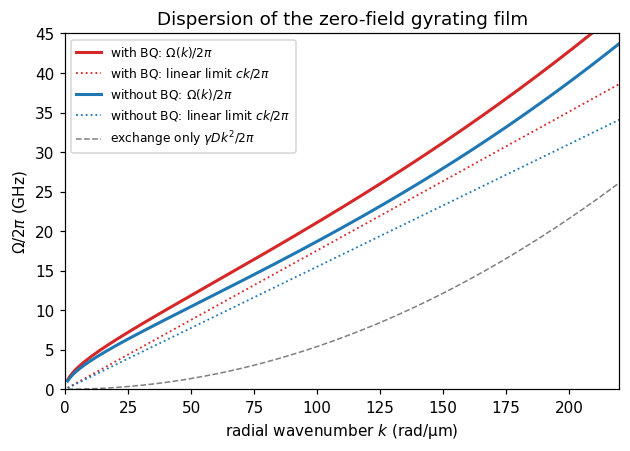

In [4]:
# dispersion curves at a fixed tilt (that of the 13 GHz / 12 GHz states), with the two limiting forms
kk = np.linspace(1e6, 2.2e8, 400)
fig, ax = plt.subplots(figsize=(6.5, 4.2))
for bq, col, lab, f0 in [(True, "C3", "with BQ", 13.09), (False, "C0", "without BQ", 11.93)]:
    w0 = 2*np.pi*f0*1e9
    ax.plot(kk/1e6, Omega(kk, w0, bq)/2/np.pi/1e9, color=col, lw=2, label=f"{lab}: $\\Omega(k)/2\\pi$")
    ax.plot(kk/1e6, c_sound(bq, w0)*kk/2/np.pi/1e9, ":", color=col, lw=1.2, label=f"{lab}: linear limit $ck/2\\pi$")
ax.plot(kk/1e6, gam*D*kk**2/2/np.pi/1e9, "--", color="gray", lw=1, label="exchange only $\\gamma Dk^2/2\\pi$")
ax.set_xlabel("radial wavenumber $k$ (rad/µm)"); ax.set_ylabel("$\\Omega/2\\pi$ (GHz)")
ax.set_xlim(0, 220); ax.set_ylim(0, 45); ax.legend(fontsize=8); ax.set_title("Dispersion of the zero-field gyrating film")
plt.show()

Three features of the curve matter for what follows. It starts at zero (Goldstone mode). It is nearly linear with a
slope close to $c$, but lies above the linear limit because the dipolar term $\tfrac12M_s(1-P)\propto k$ is
comparable to exchange in the range used by the STO. And the exchange-only guess $\gamma Dk^2$, the first thing one
tries, is several times too low in the whole relevant range: the easy-plane stiffness $(M_sP+H_B)$ multiplies the small
twist stiffness and lifts the frequency.

## 3. The selection rule $\Omega(k^*)=\omega$ (Section 6)

The static radial stray field of the fixed layer at the rim becomes, in the rotating spin frame, a microwave field at
the gyration frequency with azimuthal index $m=1$. It drives the film at exactly $\omega$, and a linear medium responds
at the drive frequency. The radial wavenumber of the resulting wave is therefore the one that the dispersion assigns
to $\omega$:

$$\Omega(k^*;\,\omega)=\omega .$$

Because the tilt inside $\Omega$ depends on $\omega$, this is a fixed-point problem when one asks the inverse question
"which gyration frequency goes with a given $k$". The dependence is weak ($\cos^2\theta_0\approx0.95$), so a plain
iteration converges in a few steps; the function below uses a root finder instead.

In [5]:
def f_of_k(k, bq):
    "self-consistent gyration frequency (GHz) such that Omega(k, w) = w"
    try:
        w = brentq(lambda w: Omega(k, w, bq) - w, 2*np.pi*0.2e9, 2*np.pi*80e9)
    except ValueError:
        return np.nan
    return w/2/np.pi/1e9

# illustrate the fixed point by hand for one wavenumber
k_demo = jn_zeros(1, 3)[-1]/R          # k R = j_{1,3}
w = 0.0
print(f"fixed-point iteration for k = {k_demo/1e6:.1f} rad/um (kR = {k_demo*R:.2f}), with BQ:")
for it in range(5):
    w = Omega(k_demo, w, True)
    print(f"   step {it}: f = {w/2/np.pi/1e9:.3f} GHz   (tilt m_z0 = {w/(gam*(Ms+HB)):.3f})")
print(f"   root finder: f = {f_of_k(k_demo, True):.3f} GHz")

fixed-point iteration for k = 63.6 rad/um (kR = 10.17), with BQ:
   step 0: f = 14.661 GHz   (tilt m_z0 = 0.245)
   step 1: f = 14.243 GHz   (tilt m_z0 = 0.238)
   step 2: f = 14.267 GHz   (tilt m_z0 = 0.238)
   step 3: f = 14.266 GHz   (tilt m_z0 = 0.238)
   step 4: f = 14.266 GHz   (tilt m_z0 = 0.238)
   root finder: f = 14.266 GHz


## 4. Test of the selection rule against all simulation runs (Section 8)

`wave_table.csv` lists, for every run of the current sweep (at $D=320$ nm) and of the diameter sweep, the gyration
frequency $f$ and the wavenumber $k$ read from the slope of the unwrapped radial phase of the $M_z$ FFT map. Runs are
kept when the $m=\pm1$ harmonic carries more than 90 % of the map's power and $f>7$ GHz (below that the states are
not clean single-mode gyrations). For each kept run the model predicts a frequency from the measured $k$ alone,
$f_{\rm theory}=\Omega(k)/2\pi$ (self-consistently), and we compare it with the simulated $f$. There is no adjustable
parameter in this comparison.

In [6]:
rows = list(csv.DictReader(open("../data/derived/wave_table.csv")))
obs = {}
for bq in (True, False):
    tag = "bq" if bq else "no_bq"
    sel = [r for r in rows if r["tag"] == tag and float(r["m_frac"]) > 0.9 and float(r["f_GHz"]) > 7]
    k = np.array([abs(float(r["k_rad_per_m"])) for r in sel])
    f = np.array([float(r["f_GHz"]) for r in sel])
    sw = np.array([r["sweep"] for r in sel])
    fth = np.array([f_of_k(ki, bq) for ki in k])
    obs[bq] = dict(k=k, f=f, sweep=sw, fth=fth)
    ratio = fth/f
    print(f"{'with BQ   ' if bq else 'without BQ'}: {len(sel):3d} runs,  f_theory/f_sim = {ratio.mean():.3f} +/- {ratio.std():.3f}"
          f"   (exchange-only would give {np.mean(gam*D*k**2/2/np.pi/1e9/f):.2f})")
allr = np.concatenate([obs[True]["fth"]/obs[True]["f"], obs[False]["fth"]/obs[False]["f"]])
print(f"all runs together: {len(allr)} points, ratio = {allr.mean():.3f} +/- {allr.std():.3f}")

with BQ   : 126 runs,  f_theory/f_sim = 1.073 +/- 0.091   (exchange-only would give 0.28)
without BQ:  51 runs,  f_theory/f_sim = 1.068 +/- 0.063   (exchange-only would give 0.21)
all runs together: 177 points, ratio = 1.072 +/- 0.084


The model reproduces the frequency from the measured wavenumber to within 7 % on average, with a spread of 8 %, over
8–35 GHz and both couplings, and it does so with the biquadratic case lying on its own curve. The alternatives fail
clearly: an exchange-only dispersion is 3–10 times too low, and assigning the pattern to $2\omega$ instead of $\omega$
would be off by a factor 1.8. The systematic +7 % is of the size expected from the azimuthal averaging of the dipolar
term, the 2 nm cell and the large wave amplitude ($\delta m_z\approx0.17$), see Section 10 of the derivation.

## 5. The disk as a cavity: Bessel functions and the frequency ladder (Section 7)

The response to an $m=1$ drive at frequency $\omega$ has the form $u(r)\,e^{\mathrm i(\phi-\omega t)}$, and away from
the rim $u$ obeys the Helmholtz equation with the $m=1$ Laplacian, i.e. Bessel's equation of order 1 in $k^*r$. The
solution that is finite at the centre is $J_1(k^*r)$: an inward and an outward wave of equal amplitude, i.e. a standing
wave, with nodes at the zeros of $J_1$ (spaced by $\lambda/2$) and $\pi$ phase steps at each node.

The rim then restricts $k^*R$ to discrete values. Its true boundary condition is not known (the outer 15 nm is a driven,
textured region), so two limits bracket it:

* free spins, rim antinode: $J_1'(kR)=0$, $k_nR=j'_{1,n}$;
* pinned spins, rim node: $J_1(kR)=0$, $k_nR=j_{1,n}$.

Each standing wave with $n$ interior antinodes lives in the window $j'_{1,n}\lesssim k_nR\lesssim j_{1,n}$. Inserting a
pinned cavity phase $x_n$ into the selection rule gives the gyration frequencies at which that standing wave fits:

$$f_n=\frac{1}{2\pi}\,\Omega\!\Big(\frac{x_n}{R}\Big).$$

In [7]:
nmax = 9
jz, jpz = jn_zeros(1, nmax), jnp_zeros(1, nmax)
print("n        :", "".join(f"{n:7d}" for n in range(1, nmax+1)))
print("j'_{1,n} :", "".join(f"{x:7.2f}" for x in jpz))
print("j_{1,n}  :", "".join(f"{x:7.2f}" for x in jz))
print("spacing  :", "       " + "".join(f"{x:7.2f}" for x in np.diff(jz)), "  -> pi =", round(np.pi, 2))

ladder = {}
for bq in (True, False):
    ladder[bq] = dict(free=np.array([f_of_k(x/R, bq) for x in jpz]),
                      pinned=np.array([f_of_k(x/R, bq) for x in jz]))
print("\nplateau ladder f_n (GHz) for R = 160 nm")
print("n                  :", "".join(f"{n:7d}" for n in range(1, nmax+1)))
for bq in (True, False):
    lab = "BQ   " if bq else "no BQ"
    print(f"{lab} rim antinode:", "".join(f"{x:7.1f}" for x in ladder[bq]['free']))
    print(f"{lab} rim node    :", "".join(f"{x:7.1f}" for x in ladder[bq]['pinned']))

n        :       1      2      3      4      5      6      7      8      9
j'_{1,n} :    1.84   5.33   8.54  11.71  14.86  18.02  21.16  24.31  27.46
j_{1,n}  :    3.83   7.02  10.17  13.32  16.47  19.62  22.76  25.90  29.05
spacing  :           3.18   3.16   3.15   3.15   3.15   3.14   3.14   3.14   -> pi = 3.14

plateau ladder f_n (GHz) for R = 160 nm
n                  :       1      2      3      4      5      6      7      8      9
BQ    rim antinode:     4.5    8.9   12.5   15.9   19.2   22.5   25.8   29.1   32.5
BQ    rim node    :     7.1   10.8   14.3   17.6   20.9   24.2   27.5   30.8   34.2
no BQ rim antinode:     4.0    7.9   11.0   14.0   17.0   19.9   22.8   25.8   28.8
no BQ rim node    :     6.3    9.6   12.6   15.5   18.4   21.4   24.3   27.3   30.4


**End-of-plateau frequencies from the simulation.** The current-sweep tables give $f(J)$ for the 320 nm disk. A jump is
detected wherever $f$ rises by more than 1 GHz between neighbouring currents, within the range $J=3.5$–$8\times10^{11}$ A/m$^2$
where the staircase is clean; the frequency just before each jump is the top of a plateau, i.e. the point at which the
standing wave with $n$ interior antinodes is fully developed. Below $J\approx3.5$ the oscillator is in its onset regime,
and above $J\approx7.5$ (BQ) or $6.5$ (no BQ) the steps fade into a quasi-continuous rise, for the same reason as in large
disks (the inward wave decays before it returns from the centre, Section 9.5 of the derivation).

In [8]:
def load_sweep(tag):
    J, F = [], []
    for r in csv.DictReader(open(f"../data/derived/j_vs_freq_{tag}.csv")):
        J.append(float(r["J"])); F.append(float(r["Frequency"]))
    return np.array(J), np.array(F)

sweeps = {True: load_sweep("bq"), False: load_sweep("no_bq")}

def plateau_ends(J, F, jmin=3.5, jmax=8.0, jump=1.0):
    m = (J >= jmin) & (J <= jmax)
    J, F = J[m], F[m]
    idx = np.where(np.diff(F) > jump)[0]
    idx = np.array([i for n, i in enumerate(idx) if n == 0 or i - idx[n-1] > 2])   # a jump spread over two currents counts once
    return J[idx], F[idx]

for bq in (True, False):
    J, F = sweeps[bq]
    Je, Fe = plateau_ends(J, F)
    print(f"{'with BQ   ' if bq else 'without BQ'}: plateau ends at J = {np.round(Je,2)}")
    print(f"             f just before jump = {np.round(Fe,1)} GHz;  steps = {np.round(np.diff(Fe),1)} GHz  (mean of first three: {np.diff(Fe)[:3].mean():.1f})")

with BQ   : plateau ends at J = [4.  5.  6.  7.  7.4]
             f just before jump = [ 5.7  9.4 13.1 16.8 19. ] GHz;  steps = [3.7 3.7 3.7 2.2] GHz  (mean of first three: 3.7)
without BQ: plateau ends at J = [3.8 4.8 5.5 6.3]
             f just before jump = [ 5.3  8.7 12.  15.4] GHz;  steps = [3.4 3.3 3.4] GHz  (mean of first three: 3.4)


**Step height.** Consecutive Bessel zeros are $\approx\pi$ apart, so consecutive rungs of the ladder differ by one half
wavelength of radial phase and, to first order,

$$\Delta f=f_{n+1}-f_n\simeq\frac{1}{2\pi}\frac{\partial\Omega}{\partial k}\frac{\pi}{R}=\frac{v_g}{2R}
\;\xrightarrow{\;\Omega\simeq ck\;}\;\frac{c}{2R},$$

the free spectral range of a cavity of length $R$. The biquadratic coupling raises the step because it raises the
wave velocity by $\approx\sqrt{(M_s+H_B)/M_s}=1.12$.

In [9]:
for bq in (True, False):
    lab = "with BQ   " if bq else "without BQ"
    k0 = 0.068e9; w0 = 2*np.pi*f_of_k(k0, bq)*1e9
    vg = (Omega(k0*1.001, w0, bq) - Omega(k0*0.999, w0, bq))/(0.002*k0)
    print(f"{lab}: c/(2R) = {c_sound(bq)/(2*R)/1e9:.2f} GHz,  v_g/(2R) at k*=68 rad/um = {vg/(2*R)/1e9:.2f} GHz,"
          f"  ladder spacing = {np.diff(ladder[bq]['pinned'])[2:6].min():.1f}-{np.diff(ladder[bq]['pinned'])[2:6].max():.1f} GHz,"
          f"  simulated steps (first three) = {np.diff(plateau_ends(*sweeps[bq])[1])[:3].mean():.1f} GHz")

with BQ   : c/(2R) = 3.53 GHz,  v_g/(2R) at k*=68 rad/um = 3.56 GHz,  ladder spacing = 3.3-3.3 GHz,  simulated steps (first three) = 3.7 GHz
without BQ: c/(2R) = 3.14 GHz,  v_g/(2R) at k*=68 rad/um = 3.17 GHz,  ladder spacing = 2.9-3.0 GHz,  simulated steps (first three) = 3.4 GHz


**Which limit do the data follow?** The simulated plateau tops sit close to the rim-antinode row of the ladder. But the
cavity phase can be read directly from the maps without the dispersion ($kR$ from the phase slope), and at the plateau
tops it takes values 0–1 rad **above** the zeros $j_{1,n}$: the fully developed standing wave is close to the pinned
(rim-node) condition. The two statements are reconciled by the 7 % upward bias of the dispersion found in Section 4,
which shifts every theoretical rung up by roughly 1 GHz, i.e. by about the gap between the two rows. The bright ring
at the rim in the amplitude maps is the driven edge texture, not a free-wave antinode. Both limits are drawn in the
figure below as the edges of a grey band.

In [10]:
for bq in (True, False):
    tag = "bq" if bq else "no_bq"
    J, F = sweeps[bq]
    Je, Fe = plateau_ends(J, F)
    kR = []
    for je in Je:   # measured kR at the last current before each jump
        cand = [r for r in rows if r["tag"] == tag and r["sweep"] == "J" and abs(float(r["J"]) - je) < 1e-6]
        kR.append(abs(float(cand[0]["k_rad_per_m"]))*R if cand else np.nan)
    print(f"{'with BQ   ' if bq else 'without BQ'}: measured kR at plateau tops = {np.round(kR,1)}")
print(f"compare j_{{1,n}} = {np.round(jz[:7],1)}  and  j'_{{1,n}} = {np.round(jpz[:7],1)}")
print("(the first entry is the n = 1 state, which has no interior node, so its phase-slope estimate of k is not meaningful)")

with BQ   : measured kR at plateau tops = [ 1.7  6.8 10.7 14.6 17.1]
without BQ: measured kR at plateau tops = [ 1.3  6.9 10.9 14. ]
compare j_{1,n} = [ 3.8  7.  10.2 13.3 16.5 19.6 22.8]  and  j'_{1,n} = [ 1.8  5.3  8.5 11.7 14.9 18.  21.2]
(the first entry is the n = 1 state, which has no interior node, so its phase-slope estimate of k is not meaningful)


## 6. The summary figure

Left: the selection rule. Every kept run is one point (measured $k$, simulated $f$); the solid curves are
$\Omega(k)/2\pi$ with no free parameter, the dotted lines the linear limit $ck/2\pi$.
Middle and right: the current sweep of the 320 nm disk against the ladder $f_n=\Omega(x_n/R)/2\pi$. Dashed lines are
the rim-antinode limit $x_n=j'_{1,n}$, the grey band extends up to the rim-node limit $x_n=j_{1,n}$; $n$ counts
interior antinodes (the maps show $n+1$ amplitude rings, rim included).

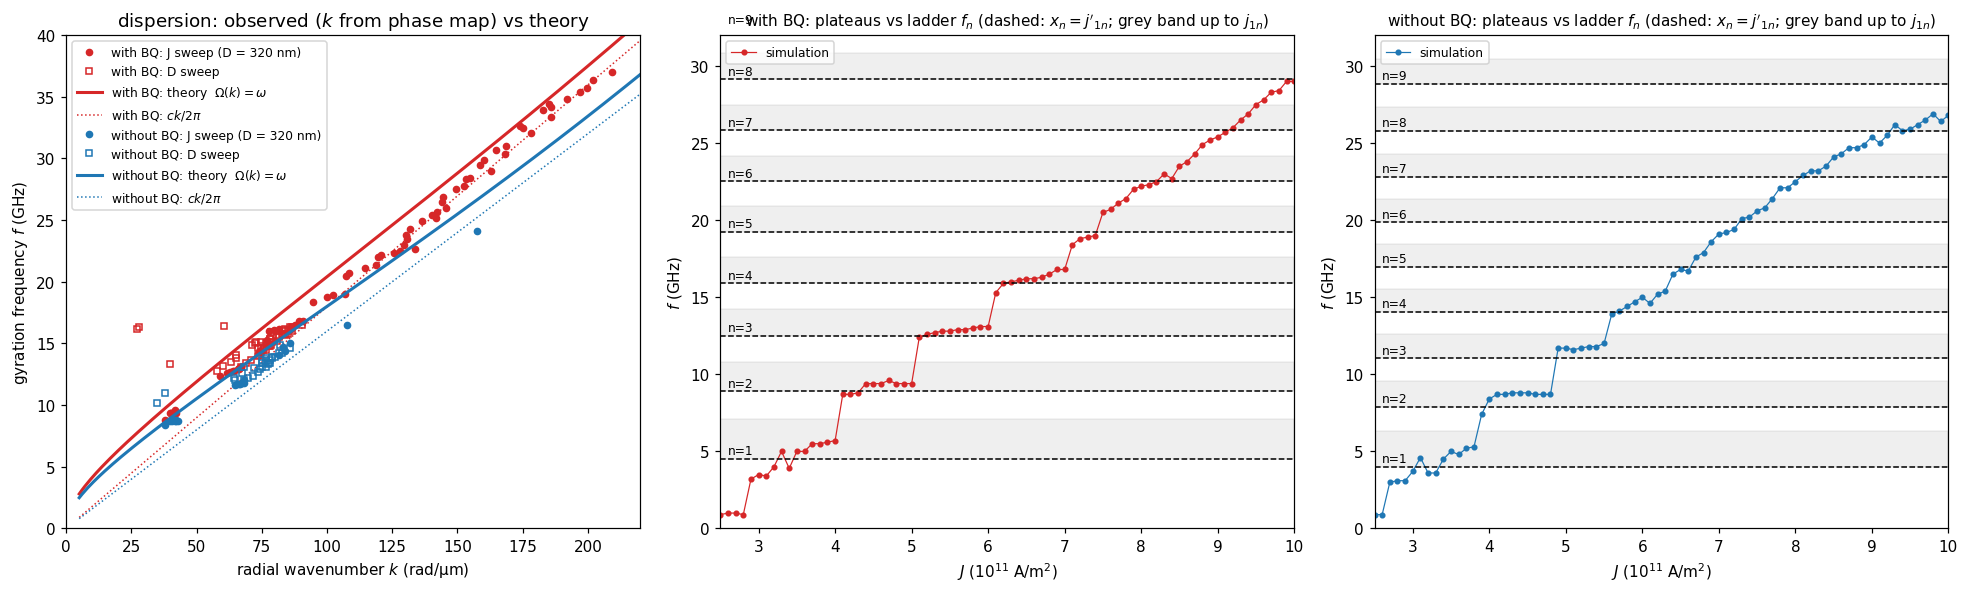

In [11]:
fig, axs = plt.subplots(1, 3, figsize=(18, 5.5))
kk = np.linspace(5e6, 2.2e8, 200)
for bq, col, lab in [(True, "C3", "with BQ"), (False, "C0", "without BQ")]:
    o = obs[bq]
    mJ, mD = o["sweep"] == "J", o["sweep"] == "D"
    axs[0].plot(o["k"][mJ]/1e6, o["f"][mJ], "o", ms=4, color=col, label=f"{lab}: J sweep (D = 320 nm)")
    axs[0].plot(o["k"][mD]/1e6, o["f"][mD], "s", ms=4, mfc="none", color=col, label=f"{lab}: D sweep")
    axs[0].plot(kk/1e6, [f_of_k(k, bq) for k in kk], "-", color=col, lw=2, label=f"{lab}: theory  $\\Omega(k)=\\omega$")
    axs[0].plot(kk/1e6, c_sound(bq)*kk/2/np.pi/1e9, ":", color=col, lw=1, label=f"{lab}: $ck/2\\pi$")
axs[0].set_xlabel("radial wavenumber $k$ (rad/µm)"); axs[0].set_ylabel("gyration frequency $f$ (GHz)")
axs[0].set_xlim(0, 220); axs[0].set_ylim(0, 40); axs[0].legend(fontsize=8)
axs[0].set_title("dispersion: observed ($k$ from phase map) vs theory")

for i, (bq, col, lab) in enumerate([(True, "C3", "with BQ"), (False, "C0", "without BQ")]):
    J, F = sweeps[bq]
    ax = axs[1+i]
    ax.plot(J, F, "o-", ms=3, color=col, lw=0.8, label="simulation")
    for n in range(1, 10):
        fn, fd = ladder[bq]["free"][n-1], ladder[bq]["pinned"][n-1]
        ax.axhline(fn, color="k", lw=1, ls="--"); ax.text(2.6, fn+0.3, f"n={n}", fontsize=8)
        ax.axhspan(fn, fd, color="gray", alpha=0.12)
    ax.set_xlim(2.5, 10); ax.set_ylim(0, 32)
    ax.set_xlabel("$J$ (10$^{11}$ A/m$^2$)"); ax.set_ylabel("$f$ (GHz)")
    ax.set_title(f"{lab}: plateaus vs ladder $f_n$ (dashed: $x_n=j'_{{1n}}$; grey band up to $j_{{1n}}$)", fontsize=10)
    ax.legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.savefig("standing_wave_theory_notebook.png", dpi=150)
plt.show()

## 7. The same rule in the diameter sweep

At fixed current the oscillator sits near a fixed frequency, so $k^*$ is nearly fixed and the cavity phase $k^*R$
grows with the radius. A new rung is reached every time it advances by $\pi$, i.e. every $\Delta R=\lambda/2$
($\Delta D\simeq\lambda\approx80$–$95$ nm), and within a plateau $f=\Omega(x_n/R)/2\pi$ **falls** as $R$ grows. The
curves below are $\Omega(j_{1,n}/R)/2\pi$ (rim-node limit) for each $n$; the points are the simulated gyration
frequencies of the diameter sweep taken from `wave_table.csv` (all runs, no selection). The full analysis of this
sawtooth, including why the steps fade and the mean frequency creeps up in large disks, is Section 9 of the derivation.

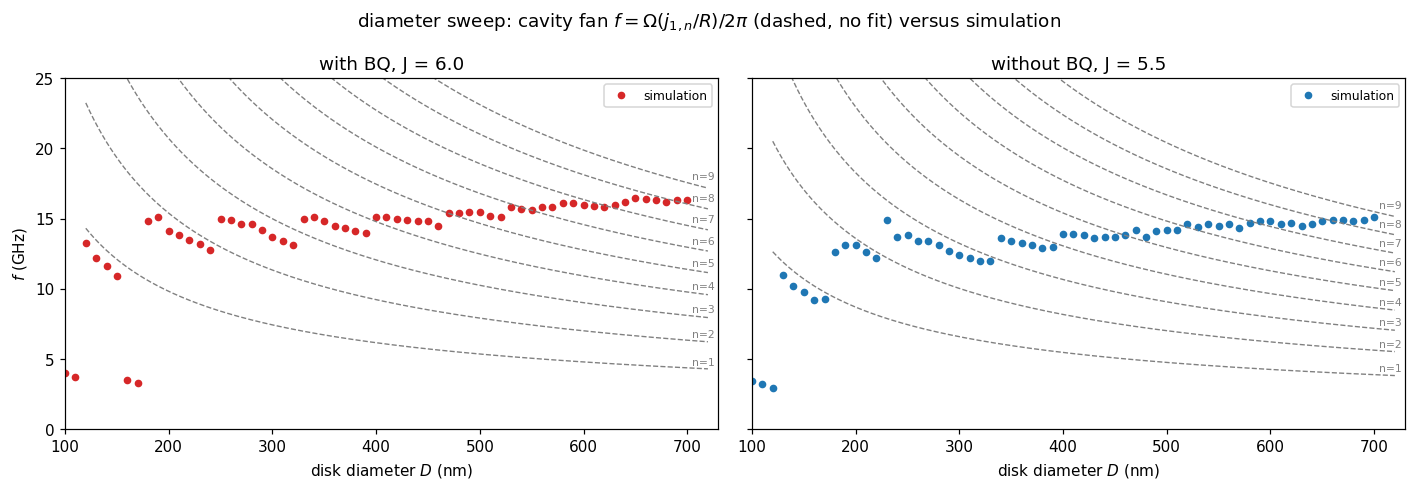

In [12]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
DD = np.linspace(120, 720, 300)
for ax, bq, col, lab in [(axs[0], True, "C3", "with BQ, J = 6.0"), (axs[1], False, "C0", "without BQ, J = 5.5")]:
    tag = "bq" if bq else "no_bq"
    sel = [r for r in rows if r["tag"] == tag and r["sweep"] == "D"]
    Dn = np.array([float(r["D_nm"]) for r in sel]); fD = np.array([float(r["f_GHz"]) for r in sel])
    ax.plot(Dn, fD, "o", ms=4, color=col, label="simulation")
    for n in range(1, 10):
        ax.plot(DD, [f_of_k(jz[n-1]/(0.5*Dd*1e-9), bq) for Dd in DD], "--", color="gray", lw=0.9)
        ax.text(705, f_of_k(jz[n-1]/(0.5*700e-9), bq)+0.2, f"n={n}", fontsize=7, color="gray")
    ax.set_xlim(100, 730); ax.set_ylim(0, 25); ax.set_xlabel("disk diameter $D$ (nm)"); ax.set_title(lab)
    ax.legend(loc="upper right", fontsize=8)
axs[0].set_ylabel("$f$ (GHz)")
plt.suptitle("diameter sweep: cavity fan $f=\\Omega(j_{1,n}/R)/2\\pi$ (dashed, no fit) versus simulation")
plt.tight_layout(); plt.show()

## 8. What the pattern looks like

For completeness, the $m=1$ standing wave at the wavenumber of the 13.1 GHz state: amplitude rings at the extrema of
$J_1$, nodes at its zeros, a $\pi$ phase step at every node, and a snapshot of $m_z\propto J_1(k^*r)\cos\phi$, which
rotates rigidly at the gyration frequency. The red and green lines are the ring positions measured in the FFT map of
that run.

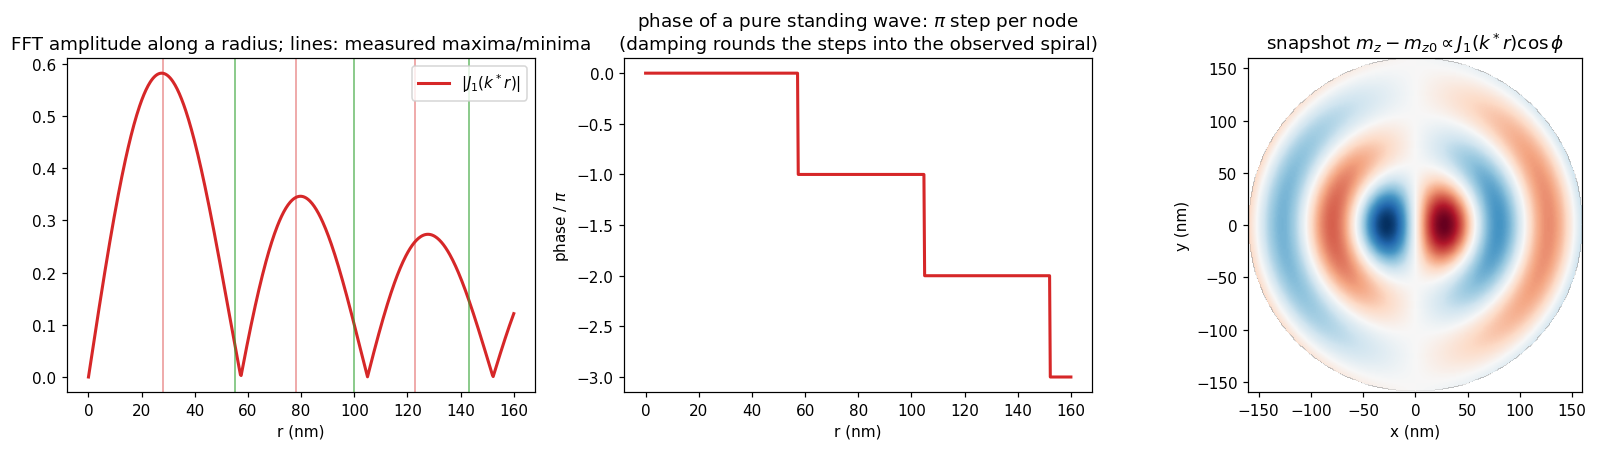

In [13]:
k = 2*np.pi/94e-9
r = np.linspace(0, 160e-9, 600)
fig, axs = plt.subplots(1, 3, figsize=(15, 4.2))
axs[0].plot(r*1e9, np.abs(j1(k*r)), "C3", lw=2, label="$|J_1(k^*r)|$")
for x in (28, 78, 123): axs[0].axvline(x, color="C3", lw=1, alpha=.5)
for x in (55, 100, 143): axs[0].axvline(x, color="C2", lw=1, alpha=.7)
axs[0].set_xlabel("r (nm)"); axs[0].set_title("FFT amplitude along a radius; lines: measured maxima/minima"); axs[0].legend()
stair = -np.pi*np.searchsorted(jn_zeros(1, 6)/k, r)
axs[1].plot(r*1e9, stair/np.pi, "C3", lw=2); axs[1].set_xlabel("r (nm)"); axs[1].set_ylabel("phase / $\\pi$")
axs[1].set_title("phase of a pure standing wave: $\\pi$ step per node\n(damping rounds the steps into the observed spiral)")
N = 301; X, Y = np.meshgrid(np.linspace(-160, 160, N), np.linspace(-160, 160, N)); RR = np.hypot(X, Y)*1e-9; PH = np.arctan2(Y, X)
Z = np.where(RR <= 160e-9, j1(k*RR)*np.cos(PH), np.nan)
axs[2].imshow(Z, extent=[-160, 160, -160, 160], cmap="RdBu_r", origin="lower"); axs[2].set_title("snapshot $m_z-m_{z0}\\propto J_1(k^*r)\\cos\\phi$")
axs[2].set_xlabel("x (nm)"); axs[2].set_ylabel("y (nm)")
plt.tight_layout(); plt.show()

## 9. Summary, and what the model does not give

* **Dispersion.** $\Omega(k)$ is the ordinary thin-film dipole–exchange dispersion of an in-plane film with zero internal
  field, with the biquadratic coupling appearing as an additional easy-plane stiffness $H_B$ next to $M_s$. No new physics
  is required; the non-obvious step is the choice of the co-rotating **spin** frame, which makes the gyrating state a
  zero-field equilibrium without changing the azimuthal index or the frequency of the $m_z$ pattern.
* **Selection rule.** $\Omega(k^*)=\omega$, because the fixed layer's static edge field is an $m=1$ microwave drive at the
  gyration frequency in that frame. Verified on all 177 clean runs to 7 % with no fitted parameter.
* **Cavity.** $J_1(k^*r)$ standing wave, rings every $\lambda/2$, $\pi$ steps in the phase; ladder of plateau
  frequencies $f_n=\Omega(x_n/R)/2\pi$ with $x_n$ between $j'_{1,n}$ and $j_{1,n}$; step height $\simeq v_g/2R$, larger
  with BQ because the wave is faster.
* **Not in this notebook.** The absolute position of the oscillator on a rung at a given current or diameter requires
  the power balance between spin torque, damping and the wave (Section 9 of the derivation, `power_balance.py`); the
  exact rim boundary condition; and the states below $D\approx180$ nm, which are not coherent gyrations.